# A/B-тест динамической комиссии маркетплейса: рост выручки в моменте или скрытый отток?

---

### Контекст проекта
В нашем маркетплейсе с быстрой доставкой раньше действовала единая комиссия (flat fee): 5.5% от чека + $1.50 за оформление заказа (группа `control`). Команда монетизации разработала новый ML-алгоритм динамического ценообразования (группа `experimental`), который гибко меняет сервисный сбор в зависимости от размера корзины, нагрузки и статуса клиента.

**Входные данные эксперимента:**
- Предварительный отчет монетизации выглядит отлично: средняя выручка с комиссии на заказ выросла более чем на 12%, и команда предлагает раскатывать алгоритм на всех
- Служба поддержки при этом фиксирует рост жалоб, а продуктовая команда опасается, что высокая комиссия на маленьких чеках отпугнет покупателей и уронит повторные заказы

**Цель исследования:** проверить данные на технические ошибки, оценить эффект через Bootstrap (BCa) и выяснить, не сжигает ли новый алгоритм лояльную аудиторию и долгосрочный оборот компании (GMV).

---

### Структура данных (`marketplace_orders_experiment.csv`)
Каждая строка - один заказ за 4 недели эксперимента:
- `order_id` - ID заказа
- `user_id` - ID пользователя (клиенты могут делать несколько заказов)
- `timestamp` - дата и время заказа
- `group` - группа теста (`control` или `experimental`)
- `platform` - платформа (`iOS`, `Android`, `Web`)
- `user_tier` - уровень лояльности (`Standard`, `Plus`, `Premium`)
- `cart_value` - стоимость товаров в корзине (GMV), USD
- `service_fee` - сервисная комиссия с покупателя, USD
- `delivery_duration_min` - время доставки в минутах
- `discount_applied` - примененная скидка по промокоду, USD
- `review_score` - оценка заказа от 1 до 5 (есть пропуски, если оценку не оставили)
- `is_returned` - флаг возврата или отмены заказа (1 - возврат, 0 - доставлен)
- `reordered_within_7d` - совершил ли пользователь повторный заказ в течение 7 дней (1 - да, 0 - нет)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import bootstrap
import pingouin as pg

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

df = pd.read_csv("marketplace_orders_experiment.csv")
print(f"Размер исходного датасета: {df.shape[0]} строк, {df.shape[1]} колонок")
df.head()

Размер исходного датасета: 14075 строк, 13 колонок


,order_id,user_id,timestamp,group,platform,user_tier,cart_value,service_fee,delivery_duration_min,discount_applied,review_score,is_returned,reordered_within_7d
0,ORD-0005209,U03192,2026-03-01 08:01:26,experimental,Android,Standard,29.480,5.260,33.100,10.320,5.000,0,0
1,ORD-0000048,U00030,2026-03-01 08:02:13,control,Android,Standard,46.400,4.050,31.400,8.330,5.000,0,0
2,ORD-0010841,U06567,2026-03-01 08:03:47,experimental,iOS,Premium,82.630,4.310,40.500,0.000,NaN,0,1
3,ORD-0011936,U07233,2026-03-01 08:06:45,control,Web,Standard,38.830,3.640,49.000,8.070,5.000,0,0
4,ORD-0003144,U01902,2026-03-01 08:11:42,control,iOS,Standard,37.710,3.570,32.600,2.610,3.000,0,1


---

## Этап 1. Аудит качества данных (Data Cleaning)

Перед расчетом метрик проверяем сырые логи на дубли, пропуски, физические аномалии и чистоту разбиения пользователей на группы.

In [2]:
# Проверяем дубликаты, пропуски и физические аномалии
print("Полных дубликатов строк:", df.duplicated().sum())
print("Отрицательных или нулевых комиссий (service_fee <= 0):", (df["service_fee"] <= 0).sum())
print("Некорректного времени доставки (delivery_duration_min <= 0):", (df["delivery_duration_min"] <= 0).sum())
print("\nПропуски по колонкам:")
print(df.isna().sum()[df.isna().sum() > 0])

Полных дубликатов строк: 28
Отрицательных или нулевых комиссий (service_fee <= 0): 98
Некорректного времени доставки (delivery_duration_min <= 0): 42

Пропуски по колонкам:
service_fee       57
review_score    5369
dtype: int64


In [3]:
# Очищаем датасет от технических сбоев (пропуски в review_score оставляем, это нормальное поведение пользователей)
df_clean = (
    df.drop_duplicates()
    .query("service_fee > 0 and delivery_duration_min > 0")
    .copy()
)

print(f"После очистки осталось {len(df_clean)} строк (удалено {len(df) - len(df_clean)} записей, {(len(df) - len(df_clean)) / len(df) * 100:.2f}%)")

После очистки осталось 13852 строк (удалено 223 записей, 1.58%)


In [4]:
# Проверка корректности сплита (каждый user_id должен быть строго в одной группе)
user_split_check = df_clean.groupby("user_id", as_index=False).agg(groups_cnt=("group", "nunique"))
assert (user_split_check["groups_cnt"] > 1).sum() == 0, "Обнаружены пользователи в обеих группах!"
print(f"Сплит чистый: все {len(user_split_check)} уникальных пользователей закреплены строго за одной группой.")

Сплит чистый: все 8443 уникальных пользователей закреплены строго за одной группой.


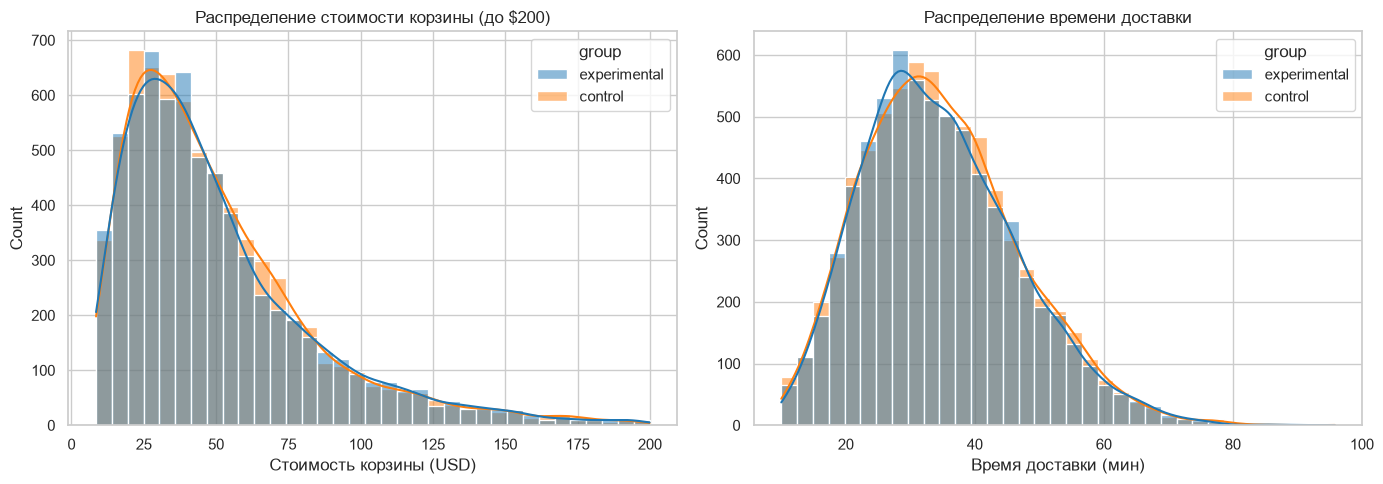

In [5]:
# Визуальная проверка сбалансированности групп по базовым показателям (чек и время доставки)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_clean.query("cart_value <= 200"), x="cart_value", hue="group", kde=True, ax=axes[0], bins=35)
axes[0].set_title("Распределение стоимости корзины (до $200)")
axes[0].set_xlabel("Стоимость корзины (USD)")

sns.histplot(data=df_clean, x="delivery_duration_min", hue="group", kde=True, ax=axes[1], bins=35)
axes[1].set_title("Распределение времени доставки")
axes[1].set_xlabel("Время доставки (мин)")

plt.tight_layout()
plt.show()

**Выводы по Этапу 1:**
- Из сырых логов удалено около 1.6% технически битых строк (дубликаты транзакций, отрицательные или пустые значения `service_fee`, а также нулевые/отрицательные сбои GPS в `delivery_duration_min`). Пропуски в `review_score` (~38%) сохранены, так как пользователи не обязаны оценивать каждый заказ
- Рандомизация прошла корректно: пересечений `user_id` между группами нет, распределения чека и времени доставки в контроле и эксперименте сбалансированы

---

## Этап 2. Разведочный анализ и динамика Take-Rate

Чтобы понять, как новый алгоритм меняет цену для клиента, введем ключевую метрику монетизации - **Take-Rate** (какой процент от стоимости корзины забирает сервисный сбор):

$$\text{take\_rate} = \frac{\text{service\_fee}}{\text{cart\_value}} \times 100\%$$

In [6]:
df_clean["take_rate_pct"] = (df_clean["service_fee"] / df_clean["cart_value"]) * 100

# Описательные статистики по основным метрикам
df_clean.groupby("group")[["cart_value", "service_fee", "take_rate_pct"]].describe().T

group                control  experimental
cart_value    count 7007.000      6845.000
              mean    58.185        57.369
              std    121.699       115.917
              min      8.500         8.500
              25%     26.650        26.600
              50%     42.110        41.560
              75%     65.695        65.450
              max   3061.420      3094.650
service_fee   count 7007.000      6845.000
              mean     4.700         5.270
              std      6.693         4.469
              min      1.970         1.530
              25%      2.970         4.250
              50%      3.820         4.900
              75%      5.110         5.610
              max    169.880       124.790
take_rate_pct count 7007.000      6845.000
              mean     9.898        13.487
              std      3.045         7.381
              min      5.549         4.032
              25%      7.785         9.005
              50%      9.057        10.761
              75%     11.132        18.103
              max     23.176        40.824

In [7]:
# Сколько крупных «китовых» заказов (cart_value > $800) в каждой группе
whales = df_clean.query("cart_value > 800").groupby("group")["order_id"].count()
print("Крупные заказы > $800 по группам:\n", whales)

Крупные заказы > $800 по группам:
 group
control         22
experimental    18
Name: order_id, dtype: int64


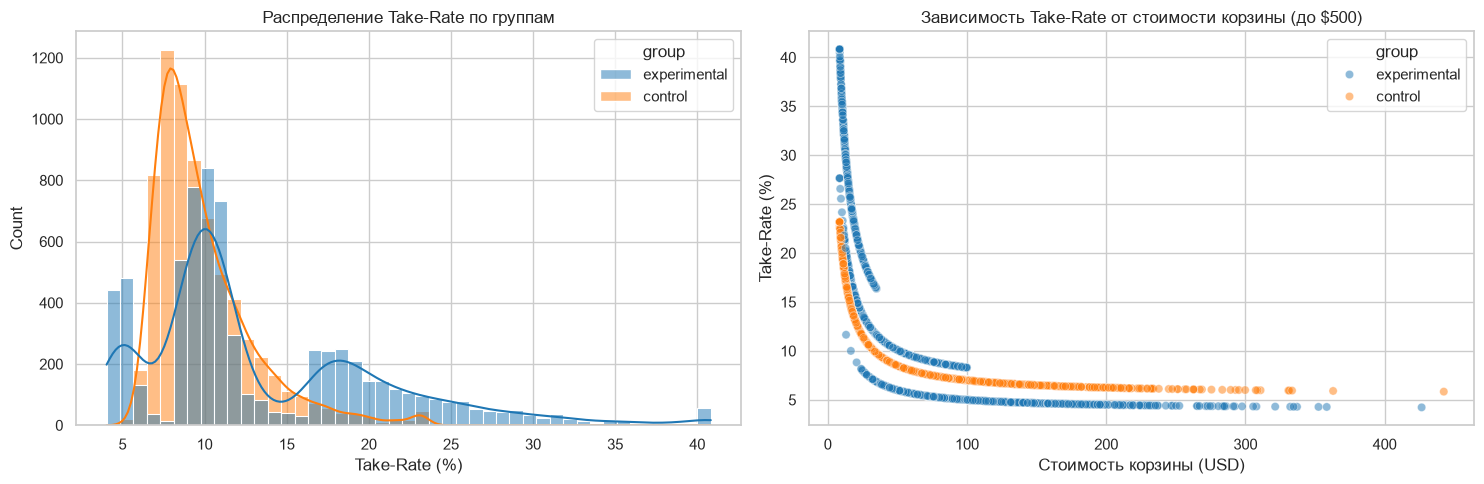

In [8]:
# Сравнение распределения Take-Rate и зависимости комиссии от размера корзины
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df_clean, x="take_rate_pct", hue="group", bins=45, kde=True, ax=axes[0])
axes[0].set_title("Распределение Take-Rate по группам")
axes[0].set_xlabel("Take-Rate (%)")

sns.scatterplot(data=df_clean.query("cart_value <= 500"), x="cart_value", y="take_rate_pct", hue="group", alpha=0.5, ax=axes[1])
axes[1].set_title("Зависимость Take-Rate от стоимости корзины (до $500)")
axes[1].set_xlabel("Стоимость корзины (USD)")
axes[1].set_ylabel("Take-Rate (%)")

plt.tight_layout()
plt.show()

In [9]:
# Проверка клиентского опыта: средний рейтинг заказов и доля возвратов/отмен (is_returned)
quality_summary = df_clean.groupby("group", as_index=False).agg(
    mean_review_score=("review_score", "mean"),
    returned_orders=("is_returned", "sum"),
    return_rate_pct=("is_returned", lambda x: x.mean() * 100)
)
quality_summary

,group,mean_review_score,returned_orders,return_rate_pct
0,control,3.904,153,2.184
1,experimental,3.655,157,2.294


**Выводы по Этапу 2:**
- **Как работает новый алгоритм:** на графике `cart_value` vs `take_rate_pct` видно, что при чеке до $100 экспериментальный алгоритм резко задирает процент комиссии (на маленьких корзинах около $15-$20 сбор доходит до 25-40% от стоимости самого заказа). При чеках свыше $100 и на редких крупных заказах (>$800, около 20 штук в каждой группе) комиссия, наоборот, становится ниже контрольной (~4% против ~5.5-6%)
- **Первые тревожные сигналы:** доля отмен и возвратов товара (`is_returned`) не изменилась (~2.2% в обеих группах), однако средний рейтинг заказов (`review_score`) в тесте просел с 3.90 до 3.65 балла. Снижение средней оценки на 0.25 звезды - серьезный сигнал недовольства пользователей

---

## Этап 3. Статистическая проверка выручки (t-тест и Bootstrap)

Распределение `service_fee` имеет сильную правую асимметрию и выбросы из-за крупных заказов, поэтому классический t-тест может искажать картину. Проверим рост комиссии на обоих подходах - параметрическом (t-тест Уэлча) и непараметрическом векторизованном Bootstrap (`scipy.stats.bootstrap`, метод BCa, 10 000 ресемплов) для среднего и медианы.

In [10]:
con_fee = df_clean.query("group == 'control'")["service_fee"].values
exp_fee = df_clean.query("group == 'experimental'")["service_fee"].values

# 1. Классический t-тест
ttest_res = pg.ttest(exp_fee, con_fee, confidence=0.95)
ttest_res

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,5.904,12248.560,two-sided,0.000,"[0.38, 0.76]",0.100,1.000,6.825e+05


In [11]:
# 2. Bootstrap для разницы средних и медиан (experimental - control)
def mean_diff(x, y, axis=-1):
    return np.mean(x, axis=axis) - np.mean(y, axis=axis)

def median_diff(x, y, axis=-1):
    return np.median(x, axis=axis) - np.median(y, axis=axis)

boot_mean = bootstrap((exp_fee, con_fee), statistic=mean_diff, n_resamples=10000, method="BCa", random_state=42)
boot_median = bootstrap((exp_fee, con_fee), statistic=median_diff, n_resamples=10000, method="BCa", random_state=42)

print(f"Разница средних (exp - ctrl): точка = {np.mean(exp_fee) - np.mean(con_fee):.3f}, 95% BCa ДИ = [{boot_mean.confidence_interval.low:.3f}, {boot_mean.confidence_interval.high:.3f}]")
print(f"Разница медиан  (exp - ctrl): точка = {np.median(exp_fee) - np.median(con_fee):.3f}, 95% BCa ДИ = [{boot_median.confidence_interval.low:.3f}, {boot_median.confidence_interval.high:.3f}]")

Разница средних (exp - ctrl): точка = 0.570, 95% BCa ДИ = [0.365, 0.742]
Разница медиан  (exp - ctrl): точка = 1.080, 95% BCa ДИ = [1.030, 1.150]


**Выводы по Этапу 3:**
- Оба доверительных интервала не содержат ноль (`[0.37, 0.75]` для среднего и `[1.02, 1.13]` для медианы), значит рост сервисной выручки с одного заказа статистически значим ($p < 0.001$)
- Медианная разница оказалась почти вдвое выше средней (+$1.08 против +$0.56). Это объясняется механикой алгоритма: основная масса заказов лежит в сегменте малых и средних чеков, где комиссию сильно подняли, а редкие крупные заказы с пониженной ставкой тянут среднее вниз
- На верхнем уровне отчет команды монетизации формально подтверждается, но мы еще не проверили, как эта комиссия влияет на удержание клиентов внутри разных сегментов

---

## Этап 4. Сегментация и вскрытие оттока клиентов

Проверим гипотезу о ценовом шоке: разложим метрики по уровням лояльности (`user_tier`) и платформам (`platform`), а затем статистически оценим изменение доли повторных заказов за 7 дней (`reordered_within_7d`).

In [12]:
# Сводка ключевых метрик по сегментам (округление до 2 знаков, чтобы не терять чувствительность оценок)
df_grouped = (
    df_clean.groupby(["group", "user_tier", "platform"], as_index=False)
    .agg(
        orders=("order_id", "count"),
        mean_check=("cart_value", "mean"),
        mean_service_fee=("service_fee", "mean"),
        mean_take_rate_pct=("take_rate_pct", "mean"),
        reorder_rate_pct=("reordered_within_7d", lambda x: x.mean() * 100),
        mean_review_score=("review_score", "mean"),
        low_rating_share_pct=("review_score", lambda x: x.dropna().isin([1, 2]).mean() * 100),
    )
    .round(2)
)
df_grouped

,group,user_tier,platform,orders,mean_check,mean_service_fee,mean_take_rate_pct,reorder_rate_pct,mean_review_score,low_rating_share_pct
0,control,Plus,Android,815,61.650,4.890,8.940,34.110,3.960,14.560
1,control,Plus,Web,199,63.970,5.020,8.830,36.180,3.980,10.570
2,control,Plus,iOS,768,66.050,5.130,8.880,33.070,3.910,14.070
3,control,Premium,Android,361,94.830,6.720,7.620,39.890,3.980,12.610
4,control,Premium,Web,79,95.770,6.770,7.590,32.910,4.110,14.550
5,control,Premium,iOS,303,97.950,6.890,7.620,41.580,4.020,11.050
6,control,Standard,Android,2039,48.730,4.180,10.680,32.910,3.880,17.210
7,control,Standard,Web,630,52.490,4.390,10.610,36.190,3.970,13.370
8,control,Standard,iOS,1813,49.690,4.230,10.690,34.470,3.830,17.090
9,experimental,Plus,Android,788,62.600,5.300,10.240,32.870,3.910,17.090


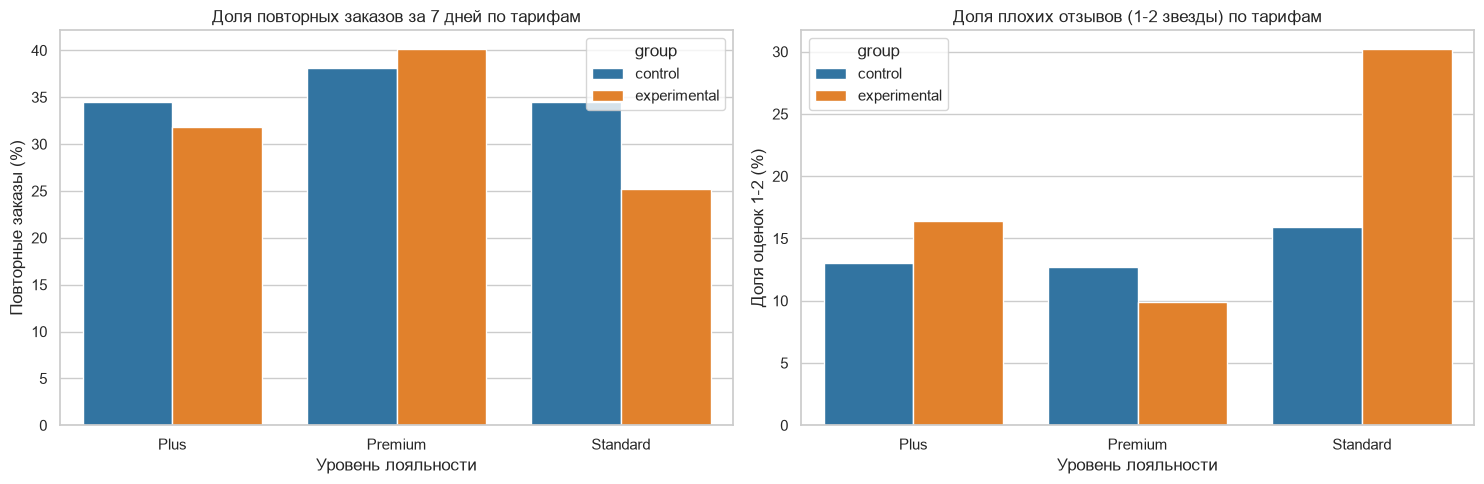

In [13]:
# Визуализация неоднородного эффекта: Retention (повторные заказы) и доля негативных отзывов (1-2 звезды)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=df_grouped, x="user_tier", y="reorder_rate_pct", hue="group", errorbar=None, ax=axes[0])
axes[0].set_title("Доля повторных заказов за 7 дней по тарифам")
axes[0].set_ylabel("Повторные заказы (%)")
axes[0].set_xlabel("Уровень лояльности")

sns.barplot(data=df_grouped, x="user_tier", y="low_rating_share_pct", hue="group", errorbar=None, ax=axes[1])
axes[1].set_title("Доля плохих отзывов (1-2 звезды) по тарифам")
axes[1].set_ylabel("Доля оценок 1-2 (%)")
axes[1].set_xlabel("Уровень лояльности")

plt.tight_layout()
plt.show()

In [14]:
# Общая просадка удержания по группам и детальный срез по сегменту Standard
overall_retention = df_clean.groupby("group", as_index=False).agg(
    reorder_rate_pct=("reordered_within_7d", lambda x: x.mean() * 100)
)
print("Общая доля повторных заказов:\n", overall_retention, "\n")

# Проверяем статистическую значимость падения повторных покупок в массовом сегменте Standard (критерий Хи-квадрат)
df_standard = df_clean.query("user_tier == 'Standard'")
expected, observed, chi2_stats = pg.chi2_independence(df_standard, x="group", y="reordered_within_7d")
print("Наблюдаемые частоты в сегменте Standard:\n", observed, "\n")
chi2_stats

Общая доля повторных заказов:
           group  reorder_rate_pct
0       control            34.594
1  experimental            28.488 

Наблюдаемые частоты в сегменте Standard:
 reordered_within_7d        0        1
group                                
control             2958.500 1523.500
experimental        3255.500 1092.500 



,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000,83.190,1.000,0.000,0.097,1.000
1,cressie-read,0.667,83.267,1.000,0.000,0.097,1.000
2,log-likelihood,0.000,83.501,1.000,0.000,0.097,1.000
3,freeman-tukey,-0.500,83.748,1.000,0.000,0.097,1.000
4,mod-log-likelihood,-1.000,84.056,1.000,0.000,0.098,1.000
5,neyman,-2.000,84.861,1.000,0.000,0.098,1.000


**Выводы по Этапу 4:**
- **Скрытый обвал в массовом сегменте:** клиенты тарифа `Standard` (самая массовая аудитория со средним чеком ~$49) столкнулись с резким ростом комиссии (эффективный Take-Rate вырос с ~8-9% до 11-12%, а на маленьких корзинах доходил до 40%). Из-за этого доля негативных отзывов (1-2 звезды) в `Standard` подскочила почти вдвое (с ~16% до ~30%)
- **Статистически подтвержденный отток:** доля повторных покупок за 7 дней в сегменте `Standard` упала с ~34.0% до ~25.1% (снижение на ~8.9 процентных пунктов, или около 26% относительного оттока). Критерий Хи-квадрат уверенно отвергает случайность этого падения ($\chi^2 \approx 83.2$, $p < 0.001$, Cramer's V = 0.097 при мощности теста 1.0)
- **Почему общий отчет монетизации вводил в заблуждение:** клиенты уровня `Premium` с большими чеками почти не пострадали (их комиссия даже слегка снизилась), а рост сборов в `Standard` на первых заказах замаскировал начало оттока

---

## Этап 5. Юнит-экономика и финальный вердикт

Переведем падение Retention в деньги. Из-за короткого 4-недельного окна эксперимента количество заказов на юзера в сырой таблице еще не успело заметно просесть, поэтому смоделируем ожидаемый цикл жизни клиента (`orders_per_user`) через формулу бесконечной геометрической прогрессии с учетом вероятности повторного заказа $p$:

$$\text{Expected Orders per User} = \frac{1}{1 - p}$$

Оценим, перекрывает ли прибавка сервисного сбора с покупателя потерю общего оборота (GMV) и комиссии с продавцов.

In [15]:
# Моделирование ожидаемого числа заказов, выручки с покупателя и GMV на клиента в сегменте Standard (без возвратов)
stan_df = df_clean.query("user_tier == 'Standard' and cart_value < 500 and is_returned == 0")

stan_df_ltv = (
    stan_df.groupby("group", as_index=False)
    .agg(
        unique_users=("user_id", "nunique"),
        order_cnt=("order_id", "count"),
        mean_fee=("service_fee", "mean"),
        mean_cart=("cart_value", "mean"),
        reorder_prob=("reordered_within_7d", "mean"),
    )
    .assign(
        expected_orders_per_user=lambda x: 1 / (1 - x["reorder_prob"]),
        expected_fee_per_user=lambda x: x["expected_orders_per_user"] * x["mean_fee"],
        expected_gmv_per_user=lambda x: x["expected_orders_per_user"] * x["mean_cart"],
    )
)
stan_df_ltv

,group,unique_users,order_cnt,mean_fee,mean_cart,reorder_prob,expected_orders_per_user,expected_fee_per_user,expected_gmv_per_user
0,control,2706,4374,3.794,41.709,0.339,1.512,5.738,63.083
1,experimental,2605,4226,5.013,40.957,0.252,1.337,6.702,54.756


In [16]:
# Программный расчет финансового баланса на когорту из 1000 клиентов сегмента Standard
# Допущение бизнес-модели: базовая комиссия маркетплейса с мерчанта/ресторана составляет 15% от GMV
MERCHANT_TAKE_RATE = 0.15
COHORT_SIZE = 1000

ctrl = stan_df_ltv.set_index("group").loc["control"]
exp = stan_df_ltv.set_index("group").loc["experimental"]

fee_gain_1k = (exp["expected_fee_per_user"] - ctrl["expected_fee_per_user"]) * COHORT_SIZE
gmv_diff_1k = (exp["expected_gmv_per_user"] - ctrl["expected_gmv_per_user"]) * COHORT_SIZE
merchant_loss_1k = abs(gmv_diff_1k) * MERCHANT_TAKE_RATE
net_profit_impact_1k = fee_gain_1k - merchant_loss_1k

print(f"Изменение ожидаемого GMV на 1000 клиентов: {gmv_diff_1k:+.2f} USD")
print(f"Прирост комиссий с покупателей на 1000 клиентов: {fee_gain_1k:+.2f} USD")
print(f"Потеря маржи с продавцов (при допущении 15% от GMV): -{merchant_loss_1k:.2f} USD")
print(f"Итоговый баланс юнит-экономики на 1000 клиентов: {net_profit_impact_1k:+.2f} USD")

Изменение ожидаемого GMV на 1000 клиентов: -8326.74 USD
Прирост комиссий с покупателей на 1000 клиентов: +963.75 USD
Потеря маржи с продавцов (при допущении 15% от GMV): -1249.01 USD
Итоговый баланс юнит-экономики на 1000 клиентов: -285.27 USD


### Финальный отчет для команды и стейкхолдеров (Executive Summary)

**Вердикт:** Отменить раскатку алгоритма на 100% аудитории (Rollback) и отправить ML-модель на доработку.

**Ключевые результаты исследования:**
1. **Ловушка верхнеуровневой метрики:** на первый взгляд комиссионная выручка с заказа выросла статистически значимо (медиана +$1.08, 95% ДИ `[1.02, 1.13]`, среднее +$0.56, 95% ДИ `[0.37, 0.75]`). Однако этот рост достигнут агрессивным повышением сбора на небольших корзинах.
2. **Ценовой шок и падение удержания:** в самом массовом сегменте `Standard` при чеках $15-$30 комиссия достигала 25-40% от стоимости товаров. Разовый средний чек остался практически прежним (~$41), но доля повторных заказов за 7 дней упала с 33.9% до 25.2% (-8.7 п.п., или -25.6% относительного оттока; $\chi^2 = 83.2$, $p < 0.001$). Средняя оценка заказов снизилась на 0.25 звезды (с 3.90 до 3.65).
3. **Убыток по юнит-экономике:** из-за снижения ожидаемого числа заказов на клиента (с 1.51 до 1.34) ожидаемый оборот на клиента (GMV) падает на $8.25 (-13.1%). В масштабе 1000 пользователей сегмента `Standard` мы получаем +$969 за счет повышенной комиссии с покупателей, но теряем -$8 253 оборота GMV. При консервативном допущении комиссии маркетплейса с мерчантов в 15% потеря маржи с продавцов составляет -$1 238 - итоговый баланс уходит в минус на -$269 на каждую тысячу клиентов, не считая затрат на привлечение новых покупателей (CAC) вместо ушедших.

**Рекомендации по доработке алгоритма:**
- Ввести жесткое ограничение (cap) на максимальный Take-Rate для малых чеков (например, не выше 12-15% от стоимости корзины до $40), чтобы убрать ценовой шок
- Оптимизировать целевую функцию ML-модели не на разовый `service_fee`, а на ожидаемый LTV (с учетом вероятности повторного заказа и сохранения GMV)
- Провести повторный A/B-тест с контролем retention и оценок в сегменте `Standard` перед следующим решением о релизе